<a href="https://colab.research.google.com/github/N3H4-Singh/AI-Engineer-Journey/blob/main/Machine-Learning/Linear-Regression/California_Housing_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# California Housing Price Prediction Using Linear Regression

## Project Objective

The objective of this project is to develop a Machine Learning model using Linear Regression to predict median house prices in California based on housing-related features such as median income, housing age, number of rooms, population, and geographical location.

The project involves:
- Exploring and understanding the housing dataset.
- Cleaning missing values and preparing the data.
- Converting categorical variables into numerical format using One-Hot Encoding.
- Splitting the dataset into training and testing sets.
- Training a Linear Regression model.
- Evaluating model performance using MAE, MSE, RMSE, and R² Score.
- Visualizing actual vs predicted prices and analyzing prediction errors.






## Dataset Description

The California Housing Prices dataset contains information about housing districts in California.

- **Dataset size:** 20,640 records
- **Original features:** 9 input features
- **Target variable:** `median_house_value`
- **File name:** `housing.csv`
- **Source:** [Kaggle – California Housing Prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices)

The dataset includes information such as median income, housing age, total rooms, total bedrooms, population, households, geographical coordinates, and ocean proximity.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/housing.csv')

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.shape

(20640, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [5]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [7]:
df['total_bedrooms'].median()

435.0

In [8]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

In [9]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes

,0
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,object


In [12]:
df['ocean_proximity'].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [13]:
df= pd.get_dummies(df, columns=['ocean_proximity'], dtype = int)

In [14]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


In [15]:
X = df.drop('median_house_value', axis=1)

y = df['median_house_value']

In [16]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 13)
Target shape: (20640,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    train_size=0.8,
    random_state=42
)

In [18]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 13)
X_test: (4128, 13)
y_train: (16512,)
y_test: (4128,)


In [19]:
from sklearn.linear_model import LinearRegression

In [20]:
model = LinearRegression()

In [21]:
# Convert all feature names to strings to resolve the mixed type error
X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

model.fit(X_train, y_train)

LinearRegression()

In [22]:
y_pred = model.predict(X_test)

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)


In [24]:
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 50670.73824097205
MSE: 4908476721.156641
RMSE: 70060.52184473537
R2 Score: 0.6254240620553587


In [25]:
import matplotlib.pyplot as plt

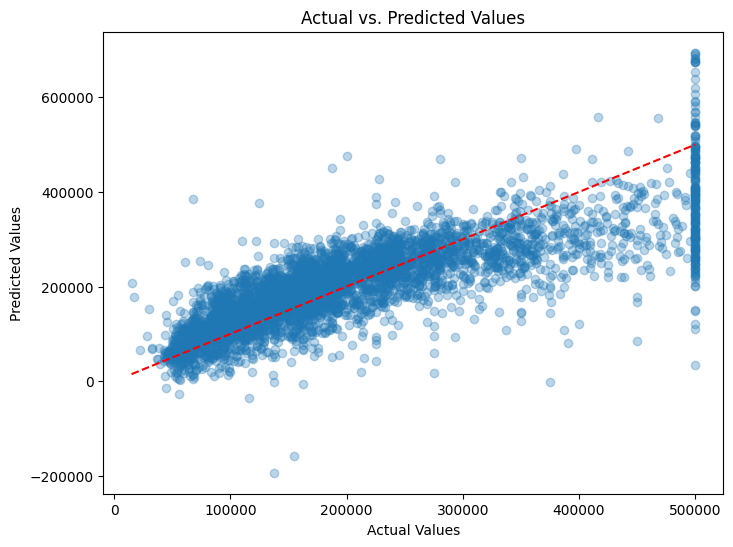

In [26]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values')
plt.show()

In [27]:
residual = y_test - y_pred

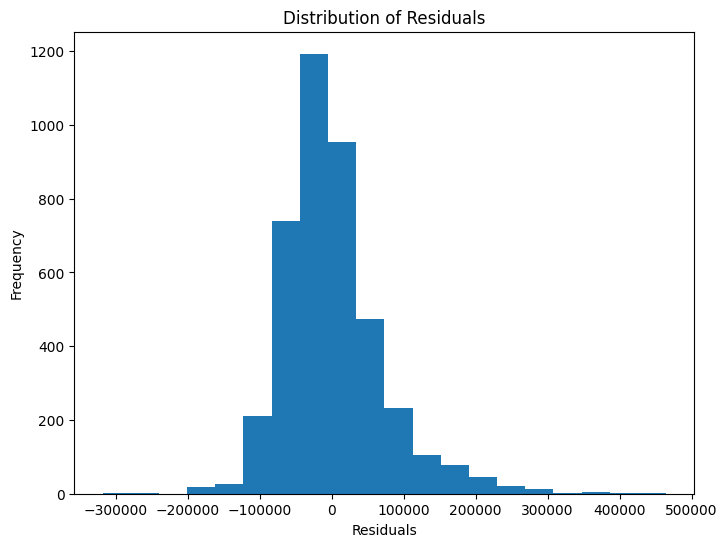

In [28]:
plt.figure(figsize=(8, 6))
plt.hist(residual, bins = 20)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')
plt.show()

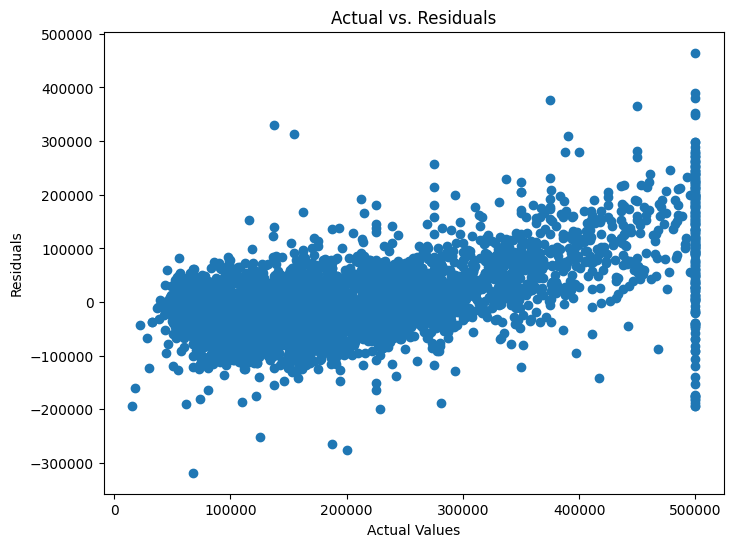

In [29]:
plt.figure(figsize= (8, 6))
plt.scatter(y_test, residual)
plt.xlabel('Actual Values')
plt.ylabel('Residuals')
plt.title('Actual vs. Residuals')
plt.show()

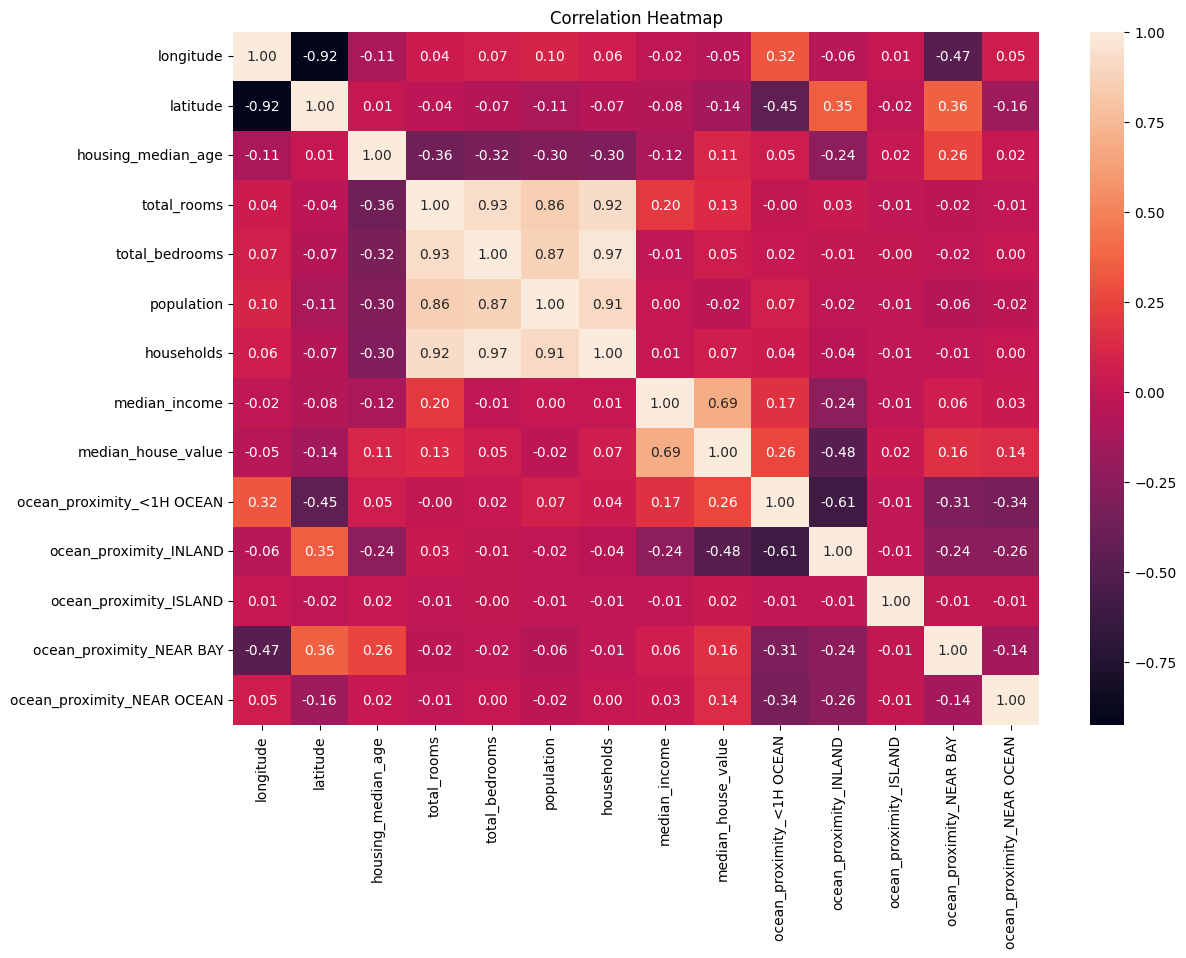

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(13, 9))
sns.heatmap(correlation, annot=True, fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

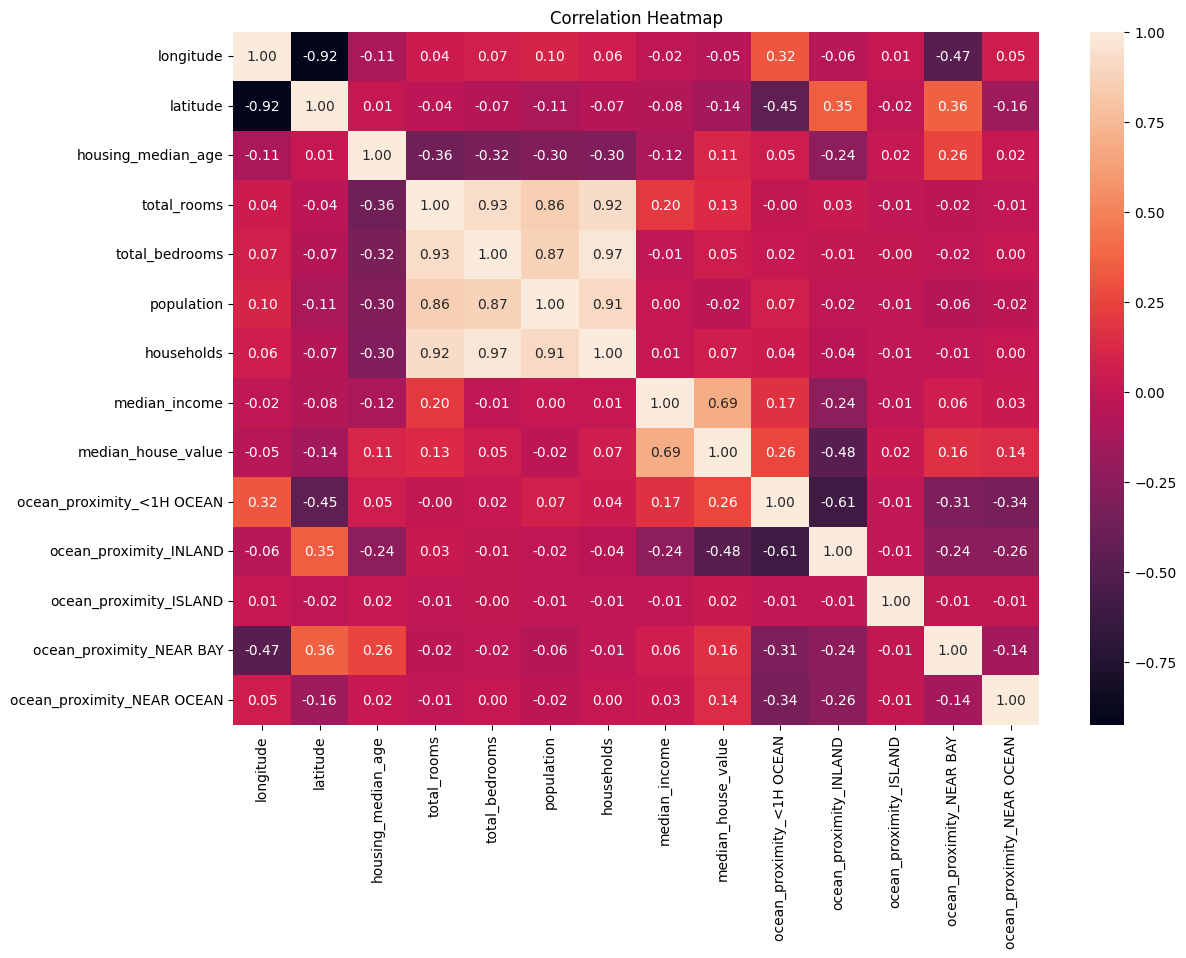

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(13, 9))
sns.heatmap(correlation, annot=True, fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

## Project Conclusion

Built a California Housing Price Prediction model using Linear Regression.

- Dataset: California Housing Prices (20,640 records).
- Missing values in `total_bedrooms` were handled using median imputation.
- Categorical data was converted using One-Hot Encoding.
- Data was split into 80% training and 20% testing.
- Model performance:
  - MAE: 50,670.74
  - RMSE: 70,060.52
  - R² Score: 0.6254

The model explains approximately 62.54% of the variation in house prices on the test dataset. This serves as a baseline model for further improvement.